# Lab 02-04 · Forced Response and Resonance

Companion to chapter [02-04](../../chapters/02-04-forced-response-and-resonance.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass

def forced(zeta, w, T, w0=1.0, n=20001):
    # y'' + 2 zeta w0 y' + w0^2 y = w0^2 cos(w t), from rest
    f = lambda t, s: [s[1], w0**2 * (math.cos(w * t) - s[0]) - 2 * zeta * w0 * s[1]]
    t = np.linspace(0, T, n)
    sol = solve_ivp(f, (0, T), [0.0, 0.0], t_eval=t, rtol=1e-10, atol=1e-12, max_step=0.05)
    return t, sol.y[0]

## Part 1 — Complex replacement by machine, and waiting for steady state

SymPy finds the steady-state gain from the characteristic polynomial; a time-domain simulation must wait for the transient to die.

**🔮 Predict:** at $Q = 20$, driven at $\omega_0$, about how many cycles until the amplitude is within 1% of its steady value?

|H(jω₀)| = 20  (should equal Q = 20)


amplitude first within 1% of 20 during cycle 29  (theory: ln(100)·Q/π = 29.3 cycles)


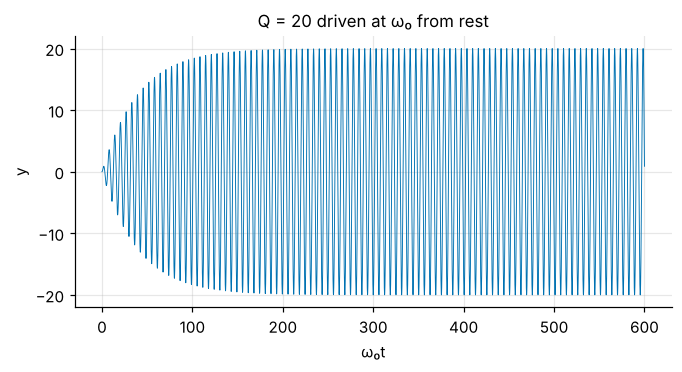

In [2]:
s, w = sp.symbols("s omega", real=True)
zeta = sp.Rational(1, 40)                  # Q = 20
p = s**2 + 2 * zeta * s + 1
H = 1 / p.subs(s, sp.I * w)
print("|H(jω₀)| =", sp.nsimplify(sp.Abs(H.subs(w, 1))), " (should equal Q = 20)")

t, y = forced(1 / 40, 1.0, 600.0, n=60001)
cyc = t / (2 * math.pi)
env = np.array([abs(y[(cyc >= k) & (cyc < k + 1)]).max() for k in range(int(cyc[-1]))])
k99 = int(np.argmax(env >= 0.99 * 20))
print(f"amplitude first within 1% of 20 during cycle {k99}  (theory: ln(100)·Q/π = {math.log(100) * 20 / math.pi:.1f} cycles)")
plt.figure(figsize=(7, 3.2)); plt.plot(t, y, lw=0.6); plt.xlabel("ω₀t"); plt.ylabel("y"); plt.title("Q = 20 driven at ω₀ from rest"); plt.show()

The build-up follows $Q(1 - e^{-\alpha t})$ with $1/\alpha = 2Q/\omega_0$: about 29 cycles to reach 99% at $Q = 20$. A measurement taken after a few cycles would badly underestimate the resonant gain.

## Part 2 — Bode plots and the resonant peak

**🔮 Predict:** at which ζ does the low-pass peak disappear?

In [3]:
r = np.logspace(-1, 1, 200001)
print(f"{'ζ':>6} {'r_peak sim':>11} {'theory':>8} {'peak sim':>9} {'theory':>8}")
for z in (0.05, 0.1, 0.25, 0.5, 0.7, 0.72):
    g = 1 / np.abs(1 - r**2 + 2j * z * r)
    k = int(np.argmax(g))
    rt = math.sqrt(1 - 2 * z * z) if z < 1 / math.sqrt(2) else float("nan")
    gt = 1 / (2 * z * math.sqrt(1 - z * z)) if z < 1 / math.sqrt(2) else 1.0
    print(f"{z:6.3f} {r[k]:11.4f} {rt:8.4f} {g[k]:9.4f} {gt:8.4f}")

     ζ  r_peak sim   theory  peak sim   theory
 0.050      0.9975   0.9975   10.0125  10.0125
 0.100      0.9899   0.9899    5.0252   5.0252
 0.250      0.9354   0.9354    2.0656   2.0656
 0.500      0.7071   0.7071    1.1547   1.1547
 0.700      0.1414   0.1414    1.0002   1.0002
 0.720      0.1000      nan    0.9996   1.0000


For ζ above $1/\sqrt2 \approx 0.707$ the largest gain is at DC (ratio 1): the peak is gone. Just below it, the peak is tiny and sits well below $\omega_0$.

## Part 3 — Half-power bandwidth

We measure the half-power frequencies of the band-pass response numerically for several $Q$.

In [4]:
r = np.linspace(0.2, 5, 2_000_001)
print(f"{'Q':>5} {'r1':>8} {'r2':>8} {'r2 - r1':>8} {'1/Q':>8} {'r1·r2':>8}")
for Q in (0.7, 2, 10, 50):
    g = 1 / np.sqrt(1 + Q**2 * (r - 1 / r) ** 2)
    above = np.where(g >= 1 / math.sqrt(2))[0]
    r1, r2 = r[above[0]], r[above[-1]]
    print(f"{Q:5} {r1:8.4f} {r2:8.4f} {r2 - r1:8.4f} {1 / Q:8.4f} {r1 * r2:8.4f}")

    Q       r1       r2  r2 - r1      1/Q    r1·r2
  0.7   0.5146   1.9432   1.4286   1.4286   1.0000
    2   0.7808   1.2808   0.5000   0.5000   1.0000
   10   0.9513   1.0512   0.1000   0.1000   1.0000
   50   0.9901   1.0100   0.0200   0.0200   1.0000


$r_2 - r_1 = 1/Q$ and $r_1r_2 = 1$ hold for every $Q$, even $Q = 0.7$ where the band is very lopsided around $\omega_0$.

## Part 4 — From beats to resonant build-up

**🔮 Predict:** what happens to the beat pattern as damping is added?

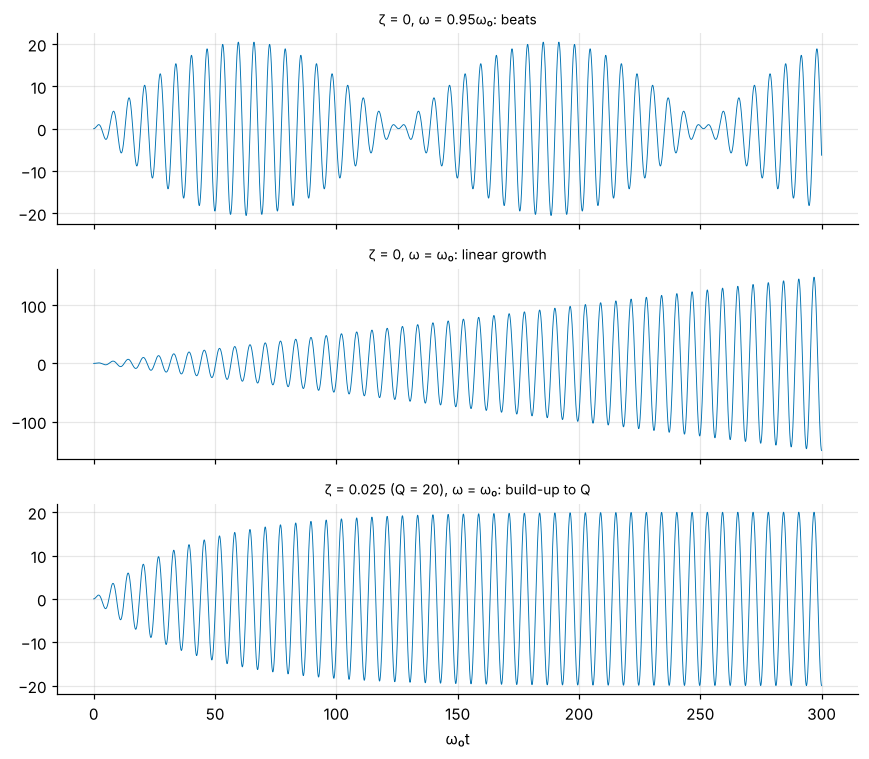

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for ax, (z, w, title) in zip(axes, [(0.0, 0.95, "ζ = 0, ω = 0.95ω₀: beats"),
                                     (0.0, 1.0, "ζ = 0, ω = ω₀: linear growth"),
                                     (0.025, 1.0, "ζ = 0.025 (Q = 20), ω = ω₀: build-up to Q")]):
    t, y = forced(z, w, 300.0)
    ax.plot(t, y, lw=0.6); ax.set_title(title, fontsize=9)
axes[-1].set_xlabel("ω₀t"); plt.tight_layout(); plt.show()

Damping turns the endless linear growth into a saturating build-up, and smooths beats into a settled steady state once the transient has decayed.

## Part 5 — ngspice

From the repository root, run `python tools/run_spice.py 02-04`:

- `rlc_ac.cir`: AC sweep of Example 02-04.2 (peak 2.066 at 1488.8 Hz, which is 9354 rad/s; gain 2 at $f_0$);
- `nfc_tank.cir`: AC sweep of the 13.56 MHz loop of Example 02-04.4 (half-power points 13.32 and 13.80 MHz; 0.2787 at the upper subcarrier sideband).

## Your turn

1. In Part 3, repeat the measurement for the *low-pass* response at ζ = 0.1. Is its half-power bandwidth also close to $\omega_0/Q$? Why only approximately?
2. In Part 1, drive slightly off resonance ($\omega = 0.98\omega_0$) at $Q = 20$ and explain the beating envelope you see during the transient.